In [1]:
# Importing Libraries
import ast
import pandas as pd
from datasets import load_dataset
import matplotlib.pyplot as plt 

# Loading Data
dataset = load_dataset('lukebarousse/data_jobs')
df = dataset['train'].to_pandas()

# Data Cleanup
df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])
df['job_skills'] = df['job_skills'].apply(lambda x: ast.literal_eval(x) if pd.notna(x) else x)

In [2]:
df

,job_title_short,job_title,job_location,job_via,job_schedule_type,job_work_from_home,search_location,job_posted_date,job_no_degree_mention,job_health_insurance,job_country,salary_rate,salary_year_avg,salary_hour_avg,company_name,job_skills,job_type_skills
0,Senior Data Engineer,Senior Clinical Data Engineer / Principal Clin...,"Watertown, CT",via Work Nearby,Full-time,False,"Texas, United States",2023-06-16 13:44:15,False,False,United States,NaN,NaN,NaN,Boehringer Ingelheim,NaN,NaN
1,Data Analyst,Data Analyst,"Guadalajara, Jalisco, Mexico",via BeBee México,Full-time,False,Mexico,2023-01-14 13:18:07,False,False,Mexico,NaN,NaN,NaN,Hewlett Packard Enterprise,"[r, python, sql, nosql, power bi, tableau]","{'analyst_tools': ['power bi', 'tableau'], 'pr..."
2,Data Engineer,"Data Engineer/Scientist/Analyst, Mid or Senior...","Berlin, Germany",via LinkedIn,Full-time,False,Germany,2023-10-10 13:14:55,False,False,Germany,NaN,NaN,NaN,ALPHA Augmented Services,"[python, sql, c#, azure, airflow, dax, docker,...","{'analyst_tools': ['dax'], 'cloud': ['azure'],..."
3,Data Engineer,LEAD ENGINEER - PRINCIPAL ANALYST - PRINCIPAL ...,"San Antonio, TX",via Diversity.com,Full-time,False,"Texas, United States",2023-07-04 13:01:41,True,False,United States,NaN,NaN,NaN,Southwest Research Institute,"[python, c++, java, matlab, aws, tensorflow, k...","{'cloud': ['aws'], 'libraries': ['tensorflow',..."
4,Data Engineer,Data Engineer- Sr Jobs,"Washington, DC",via Clearance Jobs,Full-time,False,Sudan,2023-08-07 14:29:36,False,False,Sudan,NaN,NaN,NaN,Kristina Daniel,"[bash, python, oracle, aws, ansible, puppet, j...","{'cloud': ['oracle', 'aws'], 'other': ['ansibl..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
785736,Software Engineer,DevOps Engineer,Singapura,melalui Trabajo.org,Pekerjaan tetap,False,Singapore,2023-03-13 06:16:16,False,False,Singapore,NaN,NaN,NaN,CAREERSTAR INTERNATIONAL PTE. LTD.,"[bash, python, perl, linux, unix, kubernetes, ...","{'os': ['linux', 'unix'], 'other': ['kubernete..."
785737,Data Analyst,CRM Data Analyst,"Bad Rodach, Jerman",melalui BeBee Deutschland,Pekerjaan tetap,False,Germany,2023-03-12 06:18:18,False,False,Germany,NaN,NaN,NaN,HABA FAMILYGROUP,"[sas, sas, sql, excel]","{'analyst_tools': ['sas', 'excel'], 'programmi..."
785738,Business Analyst,Commercial Analyst - Start Now,Malaysia,melalui Ricebowl,Pekerjaan tetap,False,Malaysia,2023-03-12 06:32:36,False,False,Malaysia,NaN,NaN,NaN,Lendlease Corporation,"[powerpoint, excel]","{'analyst_tools': ['powerpoint', 'excel']}"
785739,Data Engineer,"Principal Associate, Data Engineer (Remote-Eli...","Newark, New Jersey, Amerika Serikat",melalui Recruit.net,Pekerjaan tetap,False,Sudan,2023-03-12 06:32:15,False,False,Sudan,NaN,NaN,NaN,Capital One,"[python, go, nosql, sql, mongo, shell, mysql, ...","{'cloud': ['aws', 'snowflake', 'azure', 'redsh..."


### Problem #1 Statement:
Create a box plot to visualize the distribution of salary_hour_avg for Data Scientist job postings in the United States. Label the x-axis as 'Data Scientist' and the y-axis as 'Hourly Salary ($USD)'.

In [3]:
df_US_DS = df[(df["job_country"] == "United States") & (df["job_title_short"] == "Data Scientist")].copy()

In [ ]:
df_US_DS["salary_hour_avg"] # we have NaN values lets drop them

9        NaN
17       NaN
32       NaN
40       NaN
41       NaN
          ..
785578   NaN
785648   NaN
785651   NaN
785673   NaN
785692   NaN
Name: salary_hour_avg, Length: 58830, dtype: float64

In [ ]:
df_US_DS = df_US_DS.dropna(subset="salary_hour_avg") 

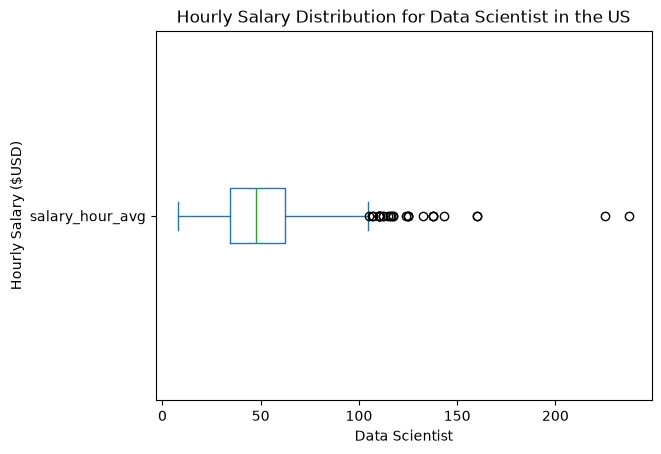

In [9]:
df_US_DS["salary_hour_avg"].plot(kind="box", vert=False)

plt.xlabel("Data Scientist")
plt.ylabel("Hourly Salary ($USD)")
plt.title('Hourly Salary Distribution for Data Scientist in the US')
plt.show()

### Problem #2 Statement:
Create a box plot to compare the distribution of salary_hour_avg for Data Analyst job postings in the United States and Canada.

Filter a DataFrame to include only 'Data Analyst' roles in these two countries.
Use list comprehension to create a list of DataFrames for each country.
Use the plt.boxplot() function to plot this list and specify the tick_labels as countries.
Set the y-axis limit to 150 and the y-axis as 'Hourly Salary ($USD)'.

In [23]:
df_DA = df[df["job_title_short"] == "Data Analyst"].copy()

In [22]:
countries = ['United States', 'Canada']

In [ ]:
df_DA = df_DA.dropna(subset="salary_hour_avg") # to drop NaN values in salary_hour_avg

In [ ]:
df_DA[df_DA["job_country"].isin(countries)] # to include in the df_DA dataframe Canada and United States countries

,job_title_short,job_title,job_location,job_via,job_schedule_type,job_work_from_home,search_location,job_posted_date,job_no_degree_mention,job_health_insurance,job_country,salary_rate,salary_year_avg,salary_hour_avg,company_name,job_skills,job_type_skills
294,Data Analyst,Business/Data Analyst,"Hartford, CT",via Dice,Contractor,False,"New York, United States",2023-07-03 13:00:08,False,False,United States,hour,NaN,52.500000,"Vector Consulting, Inc",NaN,NaN
340,Data Analyst,23-00059 BI Data Analysts + Media experience -...,California,via LinkedIn,Contractor,False,"California, United States",2023-02-28 13:01:46,True,False,United States,hour,NaN,67.500000,"iSpace, Inc.","[go, sql, aws, snowflake, tableau, looker, word]","{'analyst_tools': ['tableau', 'looker', 'word'..."
513,Data Analyst,Data Analyst,"Long Island City, NY",via Indeed,Full-time,False,"New York, United States",2023-05-09 12:59:58,False,False,United States,hour,NaN,22.500000,JK.com,"[sql, excel, tableau, power bi]","{'analyst_tools': ['excel', 'tableau', 'power ..."
840,Data Analyst,Data Analysis/ Project Coordinator/ BA,"Jersey City, NJ",via Dice,Contractor,False,"New York, United States",2023-09-19 12:59:57,False,False,United States,hour,NaN,65.000000,Ionidea,"[excel, powerpoint]","{'analyst_tools': ['excel', 'powerpoint']}"
954,Data Analyst,Financial Data Analyst,"San Antonio, TX",via Robert Half,Contractor,False,"Texas, United States",2023-06-27 13:01:51,False,False,United States,hour,NaN,76.875000,Robert Half,"[python, c, sql, sas, sas]","{'analyst_tools': ['sas'], 'programming': ['py..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
781805,Data Analyst,"Lead Data Analytic Analyst, FIN","Centertown, MO",via Snagajob,Full-time,False,"Illinois, United States",2023-08-07 06:01:15,False,True,United States,hour,NaN,23.264999,EDWARD JONES,NaN,NaN
781853,Data Analyst,Remote Jr Java programmer/Data Analyst/Data Sc...,"Indianapolis, IN",via Snagajob,Full-time and Part-time,False,Georgia,2023-09-16 06:55:42,False,False,United States,hour,NaN,30.660000,SynergisticIT,"[java, javascript, c++, sas, sas, python, orac...","{'analyst_tools': ['sas', 'tableau'], 'cloud':..."
783013,Data Analyst,Research Data Analyst,"Warner Robins, GA",via Snagajob,Full-time and Part-time,False,Georgia,2023-09-13 07:05:20,False,True,United States,hour,NaN,22.695000,"HX5, LLC",NaN,NaN
783578,Data Analyst,"Lead Data Analytic Analyst, FIN - Now Hiring","Loami, IL",via Snagajob,Full-time,False,"Illinois, United States",2023-08-07 06:01:10,False,True,United States,hour,NaN,23.760000,EDWARD JONES,NaN,NaN


In [26]:
country_data = [df_DA[df_DA['job_country'] == country]['salary_hour_avg'] for country in countries]

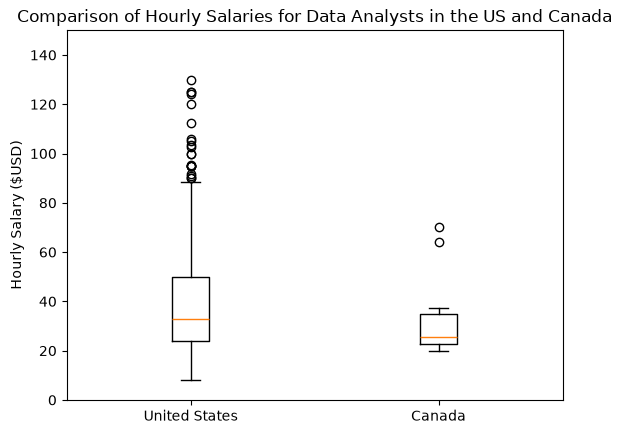

In [27]:
plt.boxplot(country_data, tick_labels=countries)
plt.xlabel('')
plt.ylabel('Hourly Salary ($USD)')
plt.ylim(0, 150)
plt.title('Comparison of Hourly Salaries for Data Analysts in the US and Canada')
plt.show()

This code uses a list comprehension to split your single DataFrame into a list of separate numerical Pandas Series—one for each country—which is the exact input format Matplotlib's plt.boxplot() requires.

Fragment-by-Fragment Breakdown
1. for country in countries
What it does: Iterates through each string in your countries list (e.g., "United States", then "Canada"), setting country to that value for each pass of the loop.

2. df_DA['job_country'] == country
What it does: Compares every row in the job_country column against the current country string.

Output: A boolean mask (True/False Series) indicating which rows belong to that specific country.

3. df_DA[...] (Filtering)
What it does: Applies the boolean mask to df_DA, returning a temporary DataFrame containing only the rows for the current country (e.g., only US rows on the 1st pass, only Canada rows on the 2nd pass).

4. ['salary_hour_avg'] (Column Selection)
What it does: Extracts just the 'salary_hour_avg' column from that filtered DataFrame.

Output: A single 1D Pandas Series containing only the hourly salary numbers for that specific country.

5. country_data = [...] (List Outer Shell)
What it does: Collects each resulting Series from every iteration into a single Python list.

End Result Structure
country_data becomes a standard Python list containing two separate Pandas Series:

### Problem #3 Statement:
Create a box plot to compare the distribution of salary_hour_avg for Data Analyst, Data Engineer, and Data Scientist job postings in Canada.
Label the x-axis as 'Job Title' and format the y-axis to have '$' before the number then label it as 'Hourly Salary (USD)'.

In [28]:
job_titles = ['Data Analyst', 'Data Engineer', 'Data Scientist']

In [30]:
df_Canada = df[df["job_country"] == "Canada"].copy()

In [33]:
df_Canada = df_Canada.dropna(subset="salary_hour_avg")

In [34]:
df_Canada[df_Canada["job_title_short"].isin(job_titles)] #outputs df with job_title_short column values of job_titles = ['Data Analyst', 'Data Engineer', 'Data Scientist']

,job_title_short,job_title,job_location,job_via,job_schedule_type,job_work_from_home,search_location,job_posted_date,job_no_degree_mention,job_health_insurance,job_country,salary_rate,salary_year_avg,salary_hour_avg,company_name,job_skills,job_type_skills
26310,Data Scientist,Data Scientist/Analyst,Canada,via LinkedIn,Contractor,False,Canada,2023-11-28 13:13:39,False,False,Canada,hour,NaN,57.500,eTeam,"[sql, python, r, word, excel, powerpoint]","{'analyst_tools': ['word', 'excel', 'powerpoin..."
70830,Data Analyst,Junior Data Analyst - Remote (Work from Home),Anywhere,via The Elite Job,Full-time and Part-time,True,Canada,2023-11-24 00:16:07,True,False,Canada,hour,NaN,25.000,The Elite Job,"[python, r, sql, tableau, power bi]","{'analyst_tools': ['tableau', 'power bi'], 'pr..."
70869,Data Analyst,Remote Data Analyst Job at Online Retailer - A...,Anywhere,via Work Wise Careers,Full-time,True,Canada,2023-11-23 00:14:40,True,False,Canada,hour,NaN,26.000,Work Wise Careers/,"[sql, excel, tableau, power bi]","{'analyst_tools': ['excel', 'tableau', 'power ..."
73362,Data Analyst,Online Data Analyst (Part-time WFH),Anywhere,via The Elite Job,Full-time and Part-time,True,Canada,2023-12-01 00:13:29,True,False,Canada,hour,NaN,25.000,The Elite Job,"[python, r, sql]","{'programming': ['python', 'r', 'sql']}"
86859,Data Scientist,Data Research and Analysis Specialist (Work fr...,Anywhere,via The Elite Job,Full-time and Part-time,True,Canada,2023-12-04 00:05:45,True,False,Canada,hour,NaN,25.000,Amazon,"[python, r, excel]","{'analyst_tools': ['excel'], 'programming': ['..."
164220,Data Engineer,Azure Data Tech Lead with 5G/Network experience,"Brampton, ON, Canada",via ZipRecruiter,Full-time,False,Canada,2023-07-18 15:35:28,True,False,Canada,hour,NaN,57.500,Danta Technologies,[azure],{'cloud': ['azure']}
164474,Data Engineer,Java Bigdata Developer,"Mississauga, ON, Canada",via LinkedIn,Contractor and Temp work,False,Canada,2023-09-27 15:20:07,False,False,Canada,hour,NaN,75.000,DISYS,"[java, sql, elasticsearch, spring, hadoop]","{'databases': ['elasticsearch'], 'libraries': ..."
180190,Data Engineer,Cloud Data Engineer,Anywhere,via Dice.com,Contractor,True,Canada,2023-07-24 15:13:36,True,False,Canada,hour,NaN,55.000,Zyreoneconsulting LLC,NaN,NaN
212339,Data Engineer,Backend Cloud Data Engineer - Node.JS,Anywhere,via Dice,Contractor,True,Canada,2023-03-31 22:14:50,False,False,Canada,hour,NaN,35.000,"KPI Partners, Inc.","[dynamodb, snowflake, aws, graphql, airflow, n...","{'cloud': ['snowflake', 'aws'], 'databases': [..."
277959,Data Engineer,Data Engineer,"Montreal, QC, Canada",via LinkedIn,Contractor,False,Canada,2023-07-13 07:09:55,False,False,Canada,hour,NaN,55.000,Applicantz,"[python, sql, snowflake, aws, pyspark, airflow...","{'analyst_tools': ['excel'], 'cloud': ['snowfl..."


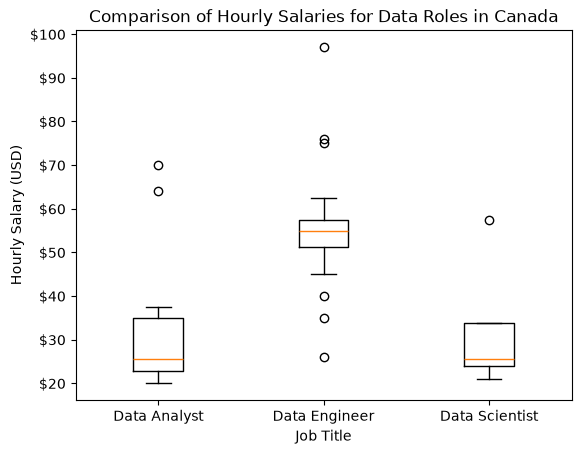

In [35]:
job_list = [df_Canada[df_Canada['job_title_short'] == job]['salary_hour_avg'] for job in job_titles]


fig, ax = plt.subplots()
ax.boxplot(job_list, tick_labels=job_titles)
ax.set_xlabel('Job Title')
ax.set_ylabel('Hourly Salary (USD)')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, pos: f'${int(y)}'))
ax.set_title('Comparison of Hourly Salaries for Data Roles in Canada')
plt.show()